# Agent Throughput Predictor: Applying Basic Machine Learning

**TL;DR:** The working code for the project: it generates simulated agent sessions, trains a neural network to predict tokens per second, validates it on unseen data, and runs tuning experiments and troubleshooting demos.

**Audience:** Readers who want to run, inspect or change the code

**Time:** about 2 minutes to run all cells; 30 to 45 minutes to work through each section

**Project documents:** [Summary](SUMMARY.md): project overview · [README](README.md): steps to set up and run the project · [Technical notes](TECHNICAL_NOTES.md): details for data results, code design, and project glossary

A small PyTorch project that predicts how fast an AI agent will generate output, in **tokens per second**, from a description of its workload. It then checks the prediction against a speed target (a service-level objective, or SLO).

> **Note:** The data in this notebook is **simulated**. It comes from a simple made-up formula with random noise, designed to behave the way agent workloads generally do (longer context and more sharing slow things down; cache reuse and bigger hardware speed things up). It is not real benchmark data. The goal is to demonstrate the machine-learning process end to end.

**What this notebook covers**

1. **Generate data:** create a simulated dataset of agent sessions
2. **Prepare data:** split into training and test sets, and normalize
3. **Build the model:** a neural network as a custom `nn.Module`
4. **Train:** run the training loop and watch the loss fall
5. **Evaluate:** test the model on data it has never seen
6. **Workload simulation:** predict speed for any workload and plan capacity
7. **Tuning experiments:** compare training settings
8. **Look inside:** watch gradients, weights and biases change
9. **Save and reload:** store the trained model for later use
10. **Troubleshooting:** common bugs, reproduced on purpose

Run the cells in order, top to bottom. On a typical laptop CPU the whole notebook takes about one to two minutes.

## 0. Setup

In [1]:
import math
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)          # makes every run produce the same numbers
print("PyTorch version:", torch.__version__)

SLO_TPS = 20.0                 # speed target: an agent should get at least 20 tokens/sec
FEATURES = ["context_tokens", "tool_calls", "subagents",
            "concurrent_agents", "cache_hit_rate", "hardware_tier"]

PyTorch version: 2.15.0+cu132


## 1. Generate data: simulated agent sessions

Each row is one simulated agent session. It records the session's six workload **features**, the model's inputs, and the **tokens per second** that session achieved, the target the model learns to predict.

The six features:

| Feature | Meaning | Range |
| --- | --- | --- |
| `context_tokens` | Tokens the agent carries from turn to turn | 1,000 – 128,000 |
| `tool_calls` | Tool calls during the session | 0 – 20 |
| `subagents` | Sub-agents it starts | 0 – 5 |
| `concurrent_agents` | Agents sharing the same hardware | 1 – 64 |
| `cache_hit_rate` | Share of earlier work reused from cache | 0.0 – 0.95 |
| `hardware_tier` | 0 = small, 1 = medium, 2 = large | 0, 1, 2 |

The `simulate_sessions()` function below creates each session's speed from a fixed formula. The formula stands in for real measurements: in a live system, each session's speed would come from actual hardware. It combines a base speed for the hardware tier with effects for each feature (more sharing and longer context slow an agent down; more cache reuse speeds it up), then adds about 8% random noise. The values were chosen by hand to behave plausibly, not taken from real benchmarks.

The formula is **hidden from the model**. During training, the network sees only each session's features and resulting speed, never the formula itself, and must learn the relationship from those examples. The training settings in later sections control *how* the model learns; they have no effect on the formula or the data it creates.

In [2]:
def simulate_sessions(n, seed=0):
    g = torch.Generator().manual_seed(seed)
    u = lambda: torch.rand(n, generator=g)

    context    = 1_000 + u() * 127_000
    tools      = torch.randint(0, 21, (n,), generator=g).float()
    subagents  = torch.randint(0, 6, (n,), generator=g).float()
    concurrent = torch.randint(1, 65, (n,), generator=g).float()
    cache_hit  = u() * 0.95
    tier       = torch.randint(0, 3, (n,), generator=g).float()

    # Hidden "physics" of the simulated AI factory
    base       = torch.tensor([110.0, 240.0, 480.0])[tier.long()]
    ctx_eff    = 1 / (1 + (context / 32_000) ** 0.8)
    share_eff  = 1 / (1 + concurrent / 16)
    tool_eff   = 1 / (1 + 0.03 * tools)
    sub_eff    = 1 / (1 + 0.08 * subagents)
    cache_eff  = 0.6 + 0.8 * cache_hit
    tps = base * ctx_eff * share_eff * tool_eff * sub_eff * cache_eff
    tps = tps * torch.exp(0.08 * torch.randn(n, generator=g))   # measurement noise

    X = torch.stack([context, tools, subagents, concurrent, cache_hit, tier], dim=1)
    return X, tps.unsqueeze(1)

X, y = simulate_sessions(5_000)
print("X shape:", X.shape, "  y shape:", y.shape)
print(f"Tokens/sec ranges from {y.min():.1f} to {y.max():.1f} (median {y.median():.1f})")
print(f"Sessions meeting the {SLO_TPS:.0f} tokens/sec target: {(y >= SLO_TPS).float().mean():.0%}")

X shape: torch.Size([5000, 6])   y shape: torch.Size([5000, 1])
Tokens/sec ranges from 1.7 to 288.6 (median 20.0)
Sessions meeting the 20 tokens/sec target: 50%


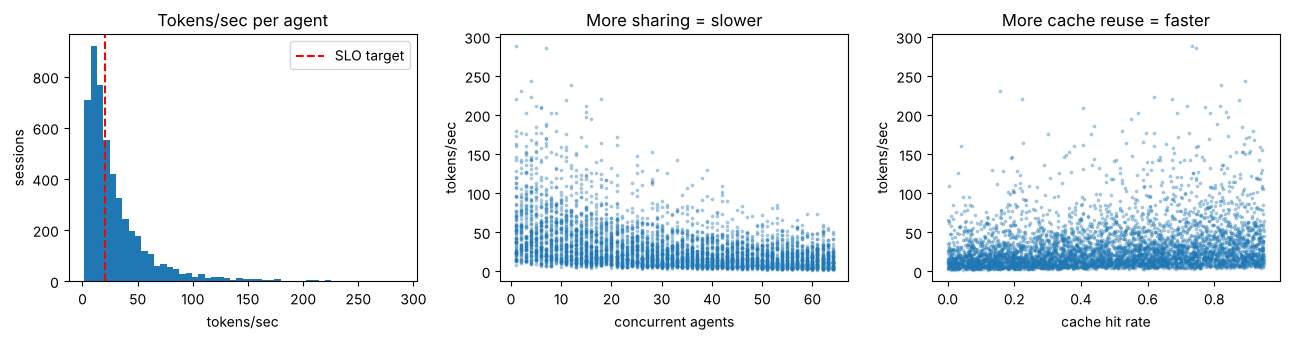

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(y.squeeze().numpy(), bins=50)
axes[0].axvline(SLO_TPS, color="red", ls="--", label="SLO target")
axes[0].set(title="Tokens/sec per agent", xlabel="tokens/sec", ylabel="sessions"); axes[0].legend()
axes[1].scatter(X[:, 3], y.squeeze(), s=3, alpha=0.3)
axes[1].set(title="More sharing = slower", xlabel="concurrent agents", ylabel="tokens/sec")
axes[2].scatter(X[:, 4], y.squeeze(), s=3, alpha=0.3)
axes[2].set(title="More cache reuse = faster", xlabel="cache hit rate", ylabel="tokens/sec")
plt.tight_layout(); plt.show()

## 2. Prepare data

Three preparation steps make training reliable:

1. **Split** into a training set (80%) the model learns from and a test set (20%) it never sees during training. The test set tells us whether the model *generalizes* instead of memorizing.
2. **Normalize the inputs.** `context_tokens` runs into the hundred-thousands while `cache_hit_rate` stays below 1. Without rescaling, the large feature dominates the gradients. We convert each feature to mean 0, standard deviation 1, using statistics from the **training set only**.
3. **Predict the log of tokens/sec.** Throughput spans from under 1 to over 200, and the effects multiply together. Taking the logarithm turns those multiplications into additions and keeps large values from dominating the loss. We convert back with `exp()` when reporting results.

In [4]:
perm = torch.randperm(len(X))
split = int(0.8 * len(X))
train_idx, test_idx = perm[:split], perm[split:]

X_train_raw, X_test_raw = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

mean, std = X_train_raw.mean(dim=0), X_train_raw.std(dim=0)
normalize = lambda t: (t - mean) / std

X_train, X_test = normalize(X_train_raw), normalize(X_test_raw)
y_train_log, y_test_log = torch.log(y_train), torch.log(y_test)

print("Training sessions:", len(X_train), "  Test sessions:", len(X_test))
print("Normalized feature means (should be ~0):", X_train.mean(dim=0).round(decimals=2))

Training sessions: 4000   Test sessions: 1000
Normalized feature means (should be ~0): tensor([-0., -0., -0., 0., -0., 0.])


## 3. Build the model: a custom `nn.Module`

`ThroughputNet` is a **subclass** of `nn.Module`. It defines its layers in `__init__` and its computation in `forward()`. When we write `model(x)`, `nn.Module.__call__` runs our `forward()`.

A single `nn.Linear` layer can only learn a straight-line relationship. This network adds two **hidden layers** with a **ReLU** activation between them. ReLU lets the network bend, so it can learn curved, interacting relationships instead of only a straight line.

In [5]:
class ThroughputNet(nn.Module):
    def __init__(self, n_features=6, hidden=64, dropout=0.0):
        super().__init__()                      # run nn.Module's own setup first
        self.layers = nn.Sequential(
            nn.Linear(n_features, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden),     nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.layers(x)                   # predicted log(tokens/sec)

model = ThroughputNet()
print(model)
print("Trainable weights and biases:", sum(p.numel() for p in model.parameters()))

ThroughputNet(
  (layers): Sequential(
    (0): Linear(in_features=6, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=64, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.0, inplace=False)
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)
Trainable weights and biases: 4673


## 4. Train

`train_model()` wraps the standard five-step training loop (predict → loss → `zero_grad` → `backward` → `step`), with two additions:

- **Mini-batches:** each step uses 64 sessions instead of the whole dataset, so the weights update many times per pass.
- **History:** it records training and test loss after every epoch so we can plot them.

All the tuning "knobs" are function arguments, which makes the experiments in section 7 one-liners.

In [6]:
def train_model(hidden=64, dropout=0.0, lr=1e-3, epochs=40, batch_size=64,
                optimizer_name="adam", weight_decay=0.0,
                Xtr=None, ytr=None, seed=0, verbose=True):
    Xtr = X_train if Xtr is None else Xtr
    ytr = y_train_log if ytr is None else ytr
    torch.manual_seed(seed)
    net = ThroughputNet(hidden=hidden, dropout=dropout)
    loss_fn = nn.MSELoss()
    if optimizer_name == "adam":
        opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        opt = torch.optim.SGD(net.parameters(), lr=lr, weight_decay=weight_decay)

    history = {"train": [], "test": []}
    for epoch in range(epochs):
        net.train()                                  # dropout ON
        order = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), batch_size):
            idx = order[i:i + batch_size]
            pred = net(Xtr[idx])                     # 1. predict
            loss = loss_fn(pred, ytr[idx])           # 2. measure how wrong
            opt.zero_grad()                          # 3. clear old gradients
            loss.backward()                          # 4. compute gradients
            opt.step()                               # 5. nudge weights and biases

        net.eval()                                   # dropout OFF for measuring
        with torch.no_grad():
            history["train"].append(loss_fn(net(Xtr), ytr).item())
            history["test"].append(loss_fn(net(X_test), y_test_log).item())
        if verbose and (epoch % 10 == 0 or epoch == epochs - 1):
            print(f"epoch {epoch:3d}   train loss {history['train'][-1]:.4f}"
                  f"   test loss {history['test'][-1]:.4f}")
    return net, history

model, history = train_model()

epoch   0   train loss 0.3227   test loss 0.3161


epoch  10   train loss 0.0127   test loss 0.0141


epoch  20   train loss 0.0090   test loss 0.0104


epoch  30   train loss 0.0077   test loss 0.0092


epoch  39   train loss 0.0072   test loss 0.0088


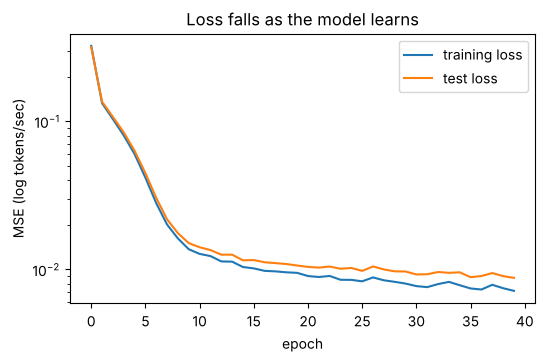

In [7]:
plt.figure(figsize=(6, 3.5))
plt.plot(history["train"], label="training loss")
plt.plot(history["test"], label="test loss")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE (log tokens/sec)")
plt.title("Loss falls as the model learns"); plt.legend(); plt.show()

## 5. Evaluate: accuracy on unseen data

We judge the model only on the **test set**. Three measures:

- **Median error:** the middle value of the gaps between predicted and actual tokens/sec, as a percentage. Half of the predictions are closer than this, half are further off.
- **R²:** how much of the variation in throughput the model explains (1.0 = perfect).
- **SLO accuracy:** how often the model correctly says whether a session meets the 20 tokens/sec target (the service-level objective, or SLO). A confusion matrix later in this section breaks these calls down further.

Because the simulated data includes about 8% random noise, even a perfect model cannot get the median error to zero.

In [8]:
def evaluate(net):
    net.eval()
    with torch.no_grad():
        pred = torch.exp(net(X_test))                       # back to tokens/sec
    pct_err = ((pred - y_test).abs() / y_test).median().item()
    ss_res = ((torch.log(pred) - y_test_log) ** 2).sum()
    ss_tot = ((y_test_log - y_test_log.mean()) ** 2).sum()
    r2 = (1 - ss_res / ss_tot).item()
    slo_acc = ((pred >= SLO_TPS) == (y_test >= SLO_TPS)).float().mean().item()
    return pred, pct_err, r2, slo_acc

pred, pct_err, r2, slo_acc = evaluate(model)
print(f"Median error:  {pct_err:.1%}")
print(f"R² (log scale): {r2:.3f}")
print(f"SLO accuracy:  {slo_acc:.1%}")

Median error:  6.0%
R² (log scale): 0.988
SLO accuracy:  97.3%


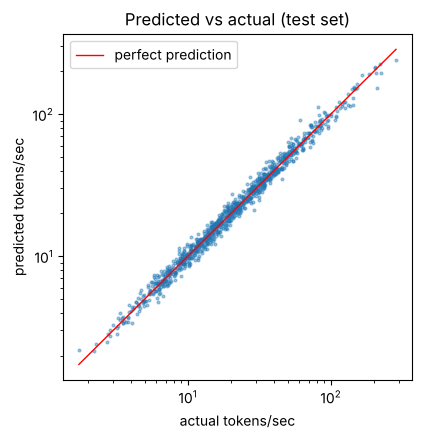

In [9]:
plt.figure(figsize=(4.5, 4.5))
plt.scatter(y_test, pred, s=4, alpha=0.4)
lim = [y_test.min().item(), y_test.max().item()]
plt.plot(lim, lim, color="red", lw=1, label="perfect prediction")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("actual tokens/sec"); plt.ylabel("predicted tokens/sec")
plt.title("Predicted vs actual (test set)"); plt.legend(); plt.show()

### Distribution of prediction errors

The median describes only the middle prediction. To see the **whole** picture, we look at every test prediction's error:

- **Signed error** = (predicted − actual) ÷ actual. Positive means the model over-predicted speed; negative means it under-predicted.
- **Percentiles** of the absolute error show how far off the model is for 25%, 50%, 75%, 90% and 95% of predictions.

A healthy model has errors centered near zero (no systematic bias) with most of them small.

Absolute error percentiles:
  25% of predictions within   2.8%
  50% of predictions within   6.0%
  75% of predictions within  10.3%
  90% of predictions within  16.0%
  95% of predictions within  18.4%
  Largest error: 47.3%
Mean signed error (bias): +1.5%   Std deviation: 9.5%
Over-predicted: 555   Under-predicted: 445


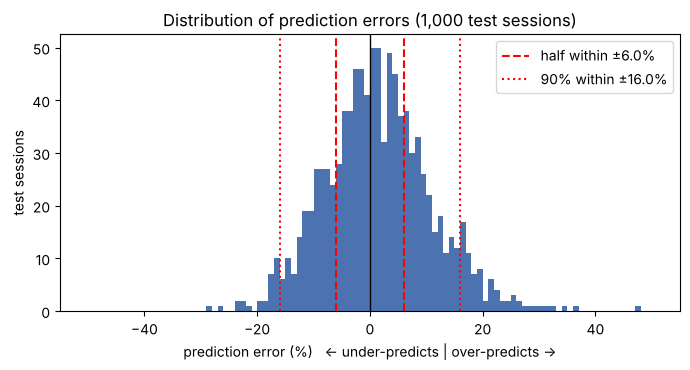

In [10]:
signed = ((pred - y_test) / y_test).squeeze() * 100        # percent
abs_err = signed.abs()

print("Absolute error percentiles:")
for q in [0.25, 0.50, 0.75, 0.90, 0.95]:
    print(f"  {q:.0%} of predictions within {torch.quantile(abs_err, q):5.1f}%")
print(f"  Largest error: {abs_err.max():.1f}%")
print(f"Mean signed error (bias): {signed.mean():+.1f}%   Std deviation: {signed.std():.1f}%")
print(f"Over-predicted: {(signed > 0).sum().item()}   Under-predicted: {(signed < 0).sum().item()}")

med, p90 = torch.quantile(abs_err, 0.5).item(), torch.quantile(abs_err, 0.9).item()
plt.figure(figsize=(7, 3.8))
plt.hist(signed.numpy(), bins=range(-50, 51), color="#4C72B0")
plt.axvline(0, color="black", lw=1)
for v, style, label in [(med, "--", f"half within ±{med:.1f}%"), (p90, ":", f"90% within ±{p90:.1f}%")]:
    plt.axvline(v, color="red", ls=style, label=label); plt.axvline(-v, color="red", ls=style)
plt.xlabel("prediction error (%)   ← under-predicts | over-predicts →")
plt.ylabel("test sessions")
plt.title("Distribution of prediction errors (1,000 test sessions)")
plt.legend(); plt.tight_layout(); plt.show()

### Pass or fail calls: confusion matrix

The model's speed prediction also becomes a yes-or-no call: will the session **meet** the 20 tokens/sec target (pass) or **miss** it (fail)? A **confusion matrix** counts the four possible outcomes, treating "meets target" as the positive result:

| | Actually meets target | Actually misses target |
| --- | --- | --- |
| **Predicted to meet** | True positive (correct pass) | False positive (**false pass**: a slow agent let through) |
| **Predicted to miss** | False negative (false fail: capacity left unused) | True negative (correct fail) |

From those counts come three measures:

- **Precision:** of the sessions the model said would pass, the share that actually did. Low precision means slow agents get through, so this matters most to operators.
- **Recall:** of the sessions that actually passed, the share the model caught. Low recall means agents are held back when the hardware could have served them.
- **F1 score:** a single score that balances precision and recall (their harmonic mean). It is high only when both are high.

**Checking for overfitting:** the cell computes these measures on both the training set and the test set. Similar scores on both mean the model has learned the general pattern; much better scores on the training set would mean it memorized its training data (see section 7d).

Training set (4,000 sessions)
  True positives 1982   False positives (false passes)  63
  False negatives  44   True negatives 1911
  Precision 96.9%   Recall 97.8%   F1 97.4%   Accuracy 97.3%

Test set (1,000 sessions)
  True positives  465   False positives (false passes)  20
  False negatives   7   True negatives  508
  Precision 95.9%   Recall 98.5%   F1 97.2%   Accuracy 97.3%



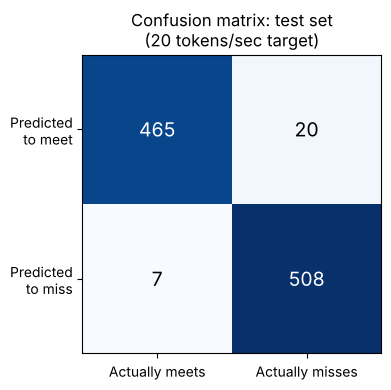

In [11]:
def pass_fail_counts(net, X_norm, y_true):
    net.eval()
    with torch.no_grad():
        pred = torch.exp(net(X_norm))
    p, a = (pred >= SLO_TPS), (y_true >= SLO_TPS)     # predicted pass, actual pass
    tp = (p & a).sum().item();  fp = (p & ~a).sum().item()
    fn = (~p & a).sum().item(); tn = (~p & ~a).sum().item()
    return tp, fp, fn, tn

def pass_fail_metrics(tp, fp, fn, tn):
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    f1 = 2 * precision * recall / (precision + recall)
    accuracy = (tp + tn) / (tp + fp + fn + tn)
    return precision, recall, f1, accuracy

results = {"Training set": pass_fail_counts(model, X_train, y_train),
           "Test set":     pass_fail_counts(model, X_test, y_test)}

for name, (tp, fp, fn, tn) in results.items():
    precision, recall, f1, accuracy = pass_fail_metrics(tp, fp, fn, tn)
    print(f"{name} ({tp + fp + fn + tn:,} sessions)")
    print(f"  True positives {tp:4d}   False positives (false passes) {fp:3d}")
    print(f"  False negatives {fn:3d}   True negatives {tn:4d}")
    print(f"  Precision {precision:.1%}   Recall {recall:.1%}   F1 {f1:.1%}   Accuracy {accuracy:.1%}\n")

tp, fp, fn, tn = results["Test set"]
matrix = [[tp, fp], [fn, tn]]
plt.figure(figsize=(4.8, 4))
plt.imshow(matrix, cmap="Blues")
for r in range(2):
    for c in range(2):
        plt.text(c, r, matrix[r][c], ha="center", va="center", fontsize=14,
                 color="white" if matrix[r][c] > 250 else "black")
plt.xticks([0, 1], ["Actually meets", "Actually misses"])
plt.yticks([0, 1], ["Predicted\nto meet", "Predicted\nto miss"])
plt.title("Confusion matrix: test set\n(20 tokens/sec target)")
plt.tight_layout(); plt.show()


## 6. Workload simulation: compare workloads and plan capacity

This trained model is used for tokens-per-second predictions, including for workloads that haven't been measured yet. `predict_tps()` takes a workload description and returns the predicted speed and whether it meets the target. The input goes through the **same normalization** as the training data; skipping that step is a classic bug (see section 10).

In [12]:
def predict_tps(context_tokens, tool_calls, subagents, concurrent_agents,
                cache_hit_rate, hardware_tier, net=None):
    net = model if net is None else net
    x = torch.tensor([[context_tokens, tool_calls, subagents,
                       concurrent_agents, cache_hit_rate, hardware_tier]], dtype=torch.float32)
    net.eval()
    with torch.no_grad():
        tps = torch.exp(net(normalize(x))).item()
    verdict = "MEETS target" if tps >= SLO_TPS else "MISSES target"
    print(f"{tps:6.1f} tokens/sec  ->  {verdict} ({SLO_TPS:.0f} tokens/sec)")
    return tps

# A coding agent with a long context, one of 32 agents sharing a medium GPU
_ = predict_tps(64_000, 8, 2, 32, 0.5, hardware_tier=1)
# Same agent, but better cache reuse and less sharing
_ = predict_tps(64_000, 8, 2, 8, 0.9, hardware_tier=1)

  18.9 tokens/sec  ->  MISSES target (20 tokens/sec)
  53.8 tokens/sec  ->  MEETS target (20 tokens/sec)


small : meets target up to 0 concurrent agents
medium: meets target up to 19 concurrent agents
large : meets target up to 61 concurrent agents


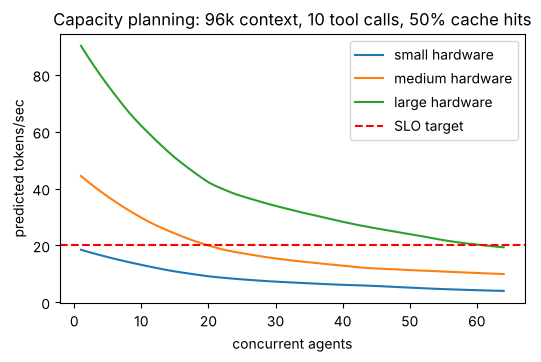

In [13]:
# How many agents can share each hardware tier before the target is missed?
counts = list(range(1, 65))
plt.figure(figsize=(6, 3.5))
for tier, name in enumerate(["small", "medium", "large"]):
    xs = torch.tensor([[96_000, 10, 2, c, 0.5, tier] for c in counts], dtype=torch.float32)
    with torch.no_grad():
        tps = torch.exp(model(normalize(xs))).squeeze()
    plt.plot(counts, tps, label=f"{name} hardware")
    ok = [c for c, t in zip(counts, tps) if t >= SLO_TPS]
    print(f"{name:6s}: meets target up to {max(ok) if ok else 0} concurrent agents")
plt.axhline(SLO_TPS, color="red", ls="--", label="SLO target")
plt.xlabel("concurrent agents"); plt.ylabel("predicted tokens/sec")
plt.title("Capacity planning: 96k context, 10 tool calls, 50% cache hits"); plt.legend(); plt.show()

## 7. Tuning experiments

Training adjusts the **weights and biases** automatically. What you tune are the **hyperparameters**: the settings that control *how* training happens. Each experiment below changes one setting and keeps everything else the same, so the effect is clear.

> **These experiments don't change the main model.** Each run in this section trains a separate model with `train_model()` to compare settings, then discards it. The main model, trained in section 4 and used in sections 5, 6 and 9, keeps the defaults set in the first line of `train_model()`:
>
> `def train_model(hidden=64, dropout=0.0, lr=1e-3, epochs=40, batch_size=64, optimizer_name="adam", weight_decay=0.0, ...)`
>
> To apply a setting you choose here, pass it as an argument in the last line of section 4, for example `model, history = train_model(lr=1e-2)`, then rerun section 4 and every section after it.

### 7a. Learning rate
The size of each weight update. Too small learns slowly; too large overshoots.

**Where the setting is changed:** the `lr` argument of `train_model()`. The code cell below compares three values with `train_model(lr=lr)`. The main model uses the default, `lr=1e-3`; to change it, use `train_model(lr=...)` in section 4.

lr=1e-05    final test loss 2.5623


lr=0.001    final test loss 0.0088


lr=0.3      final test loss 0.7538


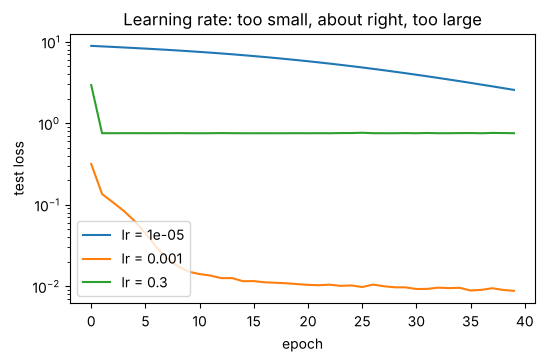

In [14]:
results = {}
for lr in [1e-5, 1e-3, 3e-1]:
    _, h = train_model(lr=lr, verbose=False)
    results[lr] = h
    print(f"lr={lr:<7}  final test loss {h['test'][-1]:.4f}")

plt.figure(figsize=(6, 3.5))
for lr, h in results.items():
    plt.plot(h["test"], label=f"lr = {lr}")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("test loss")
plt.title("Learning rate: too small, about right, too large"); plt.legend(); plt.show()

### 7b. Model size (hidden units)
More hidden units let the network represent more complex relationships, at the cost of more computation and a higher risk of memorizing.

**Where the setting is changed:** the `hidden` argument of `train_model()`, which passes it to `ThroughputNet(hidden=...)` to set the number of neurons in each hidden layer (section 3). The code cell below compares 4, 16, 64 and 256 with `train_model(hidden=hidden)`. The main model uses the default, `hidden=64`; to change it, use `train_model(hidden=...)` in section 4.

In [15]:
for hidden in [4, 16, 64, 256]:
    net, h = train_model(hidden=hidden, verbose=False)
    n_params = sum(p.numel() for p in net.parameters())
    print(f"hidden={hidden:<4} params={n_params:<6} final test loss {h['test'][-1]:.4f}")

hidden=4    params=53     final test loss 0.0243


hidden=16   params=401    final test loss 0.0120


hidden=64   params=4673   final test loss 0.0088


hidden=256  params=67841  final test loss 0.0090


### 7c. Optimizer
`SGD` and `Adam` are interchangeable subclasses of `torch.optim.Optimizer` (an example of polymorphism): the training loop does not change. Adam adapts the step size for each weight, so it usually needs less learning-rate tuning.

**Where the setting is changed:** the `optimizer_name` argument of `train_model()` (`"adam"` or `"sgd"`), together with a learning rate suited to each. The code cell below runs `train_model(optimizer_name=name, lr=lr)` with SGD at 0.01 and Adam at 0.001. The main model uses the default, `optimizer_name="adam"`; to change it, use `train_model(optimizer_name="sgd", lr=1e-2)` in section 4.

In [16]:
for name, lr in [("sgd", 1e-2), ("adam", 1e-3)]:
    _, h = train_model(optimizer_name=name, lr=lr, verbose=False)
    print(f"{name:4s} lr={lr:<6} final test loss {h['test'][-1]:.4f}")

sgd  lr=0.01   final test loss 0.0123


adam lr=0.001  final test loss 0.0088


### 7d. Overfitting and how to fix it
With only 150 training examples, a large network, and many epochs, the model can **memorize** the training set: training loss keeps falling while test loss rises. **Dropout** (randomly switching off neurons during training) and **weight decay** (a penalty on large weights) push it back toward patterns that generalize. The most reliable fix of all is **more data**, shown in the last row for comparison.

**Where the settings are changed:** the `dropout` and `weight_decay` arguments of `train_model()`. To create overfitting on purpose, the code cell below also passes `hidden=256`, `epochs=400`, and only the first 150 training sessions through `Xtr=small_X, ytr=small_y`. It trains once with no regularization, then again with `dropout=0.1, weight_decay=1e-2`. The main model uses `dropout=0.0` and `weight_decay=0.0` with all 4,000 training sessions; to add regularization, use `train_model(dropout=0.1, weight_decay=1e-2)` in section 4.

150 examples, no fix        train 0.0002   test 0.0165   gap 0.0163
150 + dropout & decay       train 0.0069   test 0.0138   gap 0.0070
4,000 examples (more data)  train 0.0072   test 0.0088   gap 0.0016


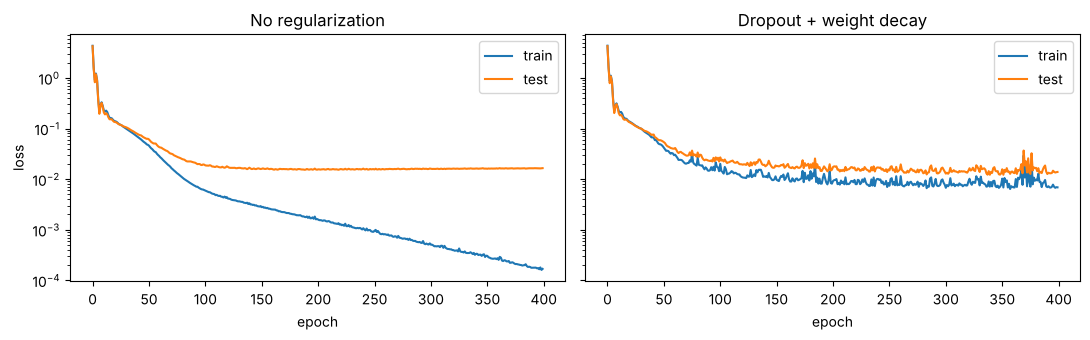

In [17]:
small_X, small_y = X_train[:150], y_train_log[:150]
_, h_over = train_model(hidden=256, epochs=400, Xtr=small_X, ytr=small_y, verbose=False)
_, h_reg  = train_model(hidden=256, epochs=400, Xtr=small_X, ytr=small_y,
                        dropout=0.1, weight_decay=1e-2, verbose=False)

for name, h in [("150 examples, no fix", h_over), ("150 + dropout & decay", h_reg),
                ("4,000 examples (more data)", history)]:
    gap = h["test"][-1] - h["train"][-1]
    print(f"{name:27s} train {h['train'][-1]:.4f}   test {h['test'][-1]:.4f}   gap {gap:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, (title, h) in zip(axes, [("No regularization", h_over), ("Dropout + weight decay", h_reg)]):
    ax.plot(h["train"], label="train"); ax.plot(h["test"], label="test")
    ax.set(title=title, xlabel="epoch", yscale="log"); ax.legend()
axes[0].set_ylabel("loss"); plt.tight_layout(); plt.show()

## 8. Look inside: gradients, weights and biases

You never set weights and biases by hand; the optimizer does. But you can **watch** it work. Below, a fresh model trains for 100 steps while we record:

- the **gradient size** for each layer (how strongly the loss "pulls" on that layer), and
- one weight and one bias from the first layer, to see them move.

Healthy training shows gradients that start larger and settle down. Gradients near zero mean learning has stalled; gradients that grow without bound mean training is unstable.

Gradient size per layer, step 0:  [0.535, 4.074, 6.409]
Gradient size per layer, step 99: [0.203, 0.317, 0.849]
Watched weight: -0.1572 -> -0.1411
Watched bias:   +0.1351 -> +0.2008


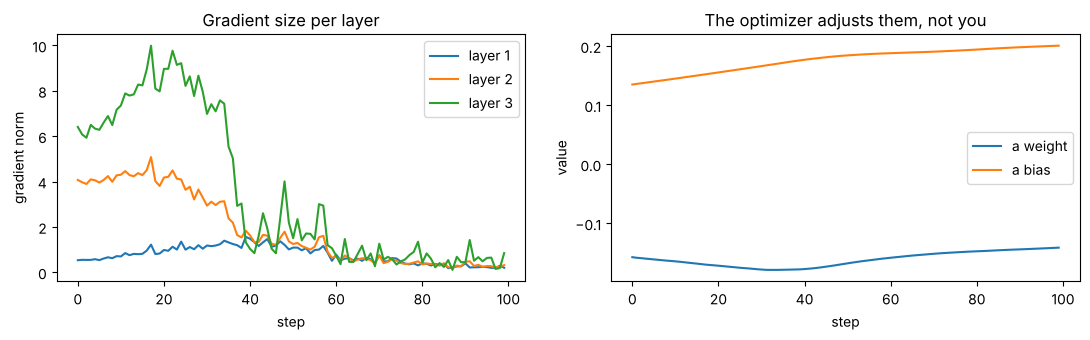

In [18]:
torch.manual_seed(0)
watch = ThroughputNet()
opt = torch.optim.Adam(watch.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()
first = watch.layers[0]                      # the first nn.Linear layer

grad_log, w_log, b_log = [], [], []
for step in range(100):
    idx = torch.randint(0, len(X_train), (64,))
    loss = loss_fn(watch(X_train[idx]), y_train_log[idx])
    opt.zero_grad()
    loss.backward()
    grad_log.append([l.weight.grad.norm().item()
                     for l in watch.layers if isinstance(l, nn.Linear)])
    w_log.append(first.weight[0, 4].item())  # weight from cache_hit_rate into neuron 0
    b_log.append(first.bias[0].item())       # bias of neuron 0
    opt.step()

print("Gradient size per layer, step 0: ", [round(g, 3) for g in grad_log[0]])
print("Gradient size per layer, step 99:", [round(g, 3) for g in grad_log[-1]])
print(f"Watched weight: {w_log[0]:+.4f} -> {w_log[-1]:+.4f}")
print(f"Watched bias:   {b_log[0]:+.4f} -> {b_log[-1]:+.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for i in range(3):
    axes[0].plot([g[i] for g in grad_log], label=f"layer {i + 1}")
axes[0].set(title="Gradient size per layer", xlabel="step", ylabel="gradient norm"); axes[0].legend()
axes[1].plot(w_log, label="a weight"); axes[1].plot(b_log, label="a bias")
axes[1].set(title="The optimizer adjusts them, not you", xlabel="step", ylabel="value"); axes[1].legend()
plt.tight_layout(); plt.show()

## 9. Save and reload

Save the trained weights **and** the normalization statistics; the model is useless without them.

In [19]:
torch.save({"state_dict": model.state_dict(), "mean": mean, "std": std},
           "throughput_model.pt")

checkpoint = torch.load("throughput_model.pt")
reloaded = ThroughputNet()
reloaded.load_state_dict(checkpoint["state_dict"])
print("Reloaded model, same prediction:")
_ = predict_tps(64_000, 8, 2, 8, 0.9, hardware_tier=1, net=reloaded)

Reloaded model, same prediction:
  53.8 tokens/sec  ->  MEETS target (20 tokens/sec)


## 10. Troubleshooting: common bugs, reproduced on purpose

Each cell below contains an **intentional bug**, shows the symptom, and then the fix. Recognizing these symptoms is most of what debugging a training run involves.

### Bug 1: Inputs not normalized
**Symptom:** loss stays high or falls very slowly. **Cause:** `context_tokens` is ~100,000 times larger than `cache_hit_rate`, so its gradients swamp everything else.

In [20]:
_, h_raw = train_model(Xtr=X_train_raw, verbose=False)        # BUG: raw inputs
print(f"Without normalization: final train loss {h_raw['train'][-1]:.4f}")
print(f"With normalization:    final train loss {history['train'][-1]:.4f}")

Without normalization: final train loss 3.6612
With normalization:    final train loss 0.0072


### Bug 2: Forgetting `optimizer.zero_grad()`
**Symptom:** loss falls much less than it should, or bounces around. **Cause:** gradients **add up** across steps (each `loss.backward()` call adds to the gradients already stored), so each update uses a growing pile of stale gradients. The cell trains the same model twice, with and without the bug.

In [21]:
def run_steps(clear_gradients, steps=300):
    torch.manual_seed(0)
    net = ThroughputNet()
    opt = torch.optim.SGD(net.parameters(), lr=1e-2)
    losses = []
    for step in range(steps):
        idx = torch.randint(0, len(X_train), (64,))
        loss = nn.MSELoss()(net(X_train[idx]), y_train_log[idx])
        if clear_gradients:
            opt.zero_grad()          # the line the buggy version forgets
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return losses

good, bad = run_steps(True), run_steps(False)          # BUG in the second run
for step in [0, 100, 200, 299]:
    print(f"step {step:3d}   with zero_grad {good[step]:.4f}   without {bad[step]:.4f}")

step   0   with zero_grad 10.3018   without 10.3018
step 100   with zero_grad 0.0931   without 0.7364
step 200   with zero_grad 0.0555   without 0.4200
step 299   with zero_grad 0.0365   without 0.8785


### Bug 3: Shape mismatch between predictions and targets
**Symptom:** a `UserWarning` about broadcasting, and a model that learns nothing useful. **Cause:** predictions have shape `[N, 1]` but the targets were flattened to `[N]`. PyTorch silently compares every prediction with every target. Always print `.shape` when something looks wrong.

In [22]:
import warnings
preds = torch.zeros(5, 1)
targets_flat = torch.ones(5)                           # BUG: shape [5], not [5, 1]
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    nn.MSELoss()(preds, targets_flat)
    print("Warning:", str(w[0].message)[:110], "...")
print("pred shape:", preds.shape, "  target shape:", targets_flat.shape)
print("Fix: targets_flat.unsqueeze(1) ->", targets_flat.unsqueeze(1).shape)

pred shape: torch.Size([5, 1])   target shape: torch.Size([5])
Fix: targets_flat.unsqueeze(1) -> torch.Size([5, 1])


### Bug 4: Learning rate far too high
**Symptom:** loss jumps to huge values, `inf`, or `nan`. **Cause:** each update overshoots further than the last. **Fix:** lower the learning rate by 10× and retrain.

In [23]:
_, h_hot = train_model(optimizer_name="sgd", lr=2.0, epochs=5, verbose=False)   # BUG
print("Test loss by epoch:", [f"{v:.3g}" for v in h_hot["test"]])

Test loss by epoch: ['nan', 'nan', 'nan', 'nan', 'nan']


### Bug 5: Forgetting to normalize new inputs at prediction time
**Symptom:** wildly wrong predictions from a model that tested well. **Cause:** the model learned on normalized inputs, so raw numbers look like extreme values it has never seen.

In [24]:
raw = torch.tensor([[64_000, 8, 2, 8, 0.9, 1]], dtype=torch.float32)
with torch.no_grad():
    wrong = torch.exp(model(raw)).item()               # BUG: no normalize()
    right = torch.exp(model(normalize(raw))).item()
print(f"Without normalize(): {wrong:,.1f} tokens/sec   (inf = number too large to represent)")
print(f"With normalize():    {right:,.1f} tokens/sec")

Without normalize(): inf tokens/sec   (inf = number too large to represent)
With normalize():    53.8 tokens/sec


## Summary

- A six-input neural network learned the hidden throughput formula from 4,000 simulated sessions and predicts unseen sessions closely enough to answer capacity questions.
- Data preparation (normalization, log target, train/test split) mattered as much as the network itself.
- Tuning is about **hyperparameters**; the optimizer handles the weights and biases.
- Most training problems announce themselves through the loss curve and tensor shapes.

**Ideas to extend it:** add a second output for time-to-first-token, one-hot encode `hardware_tier`, or replace the simulated data with measurements from a real benchmark.